# CompuOpti — staffing collaborators on projects

Decision Modelling project, MSc AI, CentraleSupélec 2026–27.

CompuOpti has a handful of software engineers and a list of client projects. Each
project needs a certain number of person-days of each of several qualifications,
pays a fixed amount if it is **completely** finished, and costs a penalty for each
day it runs past its due date. Each engineer holds only some qualifications and
has leave days booked. Not every project can be staffed, so some have to be
dropped.

The question is which projects to take and who works on what each day.

This notebook contains the whole study:

| § | |
|---|---|
| 1 | The data, and the notation used throughout |
| 2 | The model: variables, constraints, objectives |
| 3 | One objective at a time — maximum profit |
| 4 | Three objectives — what "best" means when you have more than one |
| 5 | Computing the complete set of non-dominated solutions |
| 6 | Results on the three given instances |
| 7 | Checking the results are right |
| 8 | A generator, and how the method scales |
| 9 | What the model does not capture |

Everything the notebook needs is in the `compuopti` package next to it, so the
code here stays short enough to read.

In [1]:
import sys, os, pickle, time
sys.path.insert(0, "..")          # the package sits one level up

import matplotlib.pyplot as plt
import compuopti as co

INSTANCES = "../instances"
RESULTS = "../results"
os.makedirs(RESULTS, exist_ok=True)

# Load a stored result, or compute and store it. The heavy cells use this so
# the notebook renders without re-solving everything from scratch.
def cached(name, compute):
    path = f"{RESULTS}/{name}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    value = compute()
    if value is not None:
        with open(path, "wb") as f:
            pickle.dump(value, f)
    return value

## 1. The data and the notation

A JSON instance gives a horizon, a set of qualifications, the staff (skills and
leave), and the jobs (required person-days per qualification, gain, due date,
daily penalty). `load_instance` turns it into a dict whose keys are the symbols
used in the model, so the code below reads like the formulation.

| symbol | meaning |
|---|---|
| $h$, $\mathcal H = \{1,\dots,h\}$ | horizon, in working days |
| $\mathcal Q$ | the set of qualifications |
| $\mathcal S$ | the staff |
| $\mathcal Q^S_i \subseteq \mathcal Q$ | qualifications held by person $i$ |
| $\mathcal V_i \subseteq \mathcal H$ | leave days of person $i$ |
| $\mathcal J$ | the jobs |
| $\mathcal Q^J_j \subseteq \mathcal Q$ | qualifications job $j$ needs |
| $n_{j,k}$ | person-days of qualification $k$ that job $j$ needs |
| $g_j$ | gain if job $j$ is completed |
| $d_j$ | due date of job $j$ |
| $c_j$ | penalty per day job $j$ finishes late |

Everything in that table is **data**. The decision variables in §2 are the only
things the solver chooses.

In [2]:
toy = co.load_instance(f"{INSTANCES}/toy_instance.json")
medium = co.load_instance(f"{INSTANCES}/medium_instance.json")
large = co.load_instance(f"{INSTANCES}/large_instance.json")

for inst, name in [(toy, "toy"), (medium, "medium"), (large, "large")]:
    s = co.instance_stats(inst)
    print(f"{name:<7} {s['staff']} staff, {s['jobs']} jobs, {s['quals']} quals, "
          f"horizon {s['horizon']:>2} | demand {s['demand']:>3} person-days vs "
          f"capacity {s['capacity']:>3} (load {s['load']}) | total gain {s['total_gain']}")

toy     3 staff, 5 jobs, 3 quals, horizon  5 | demand  14 person-days vs capacity  13 (load 1.08) | total gain 80
medium  5 staff, 15 jobs, 10 quals, horizon 22 | demand 135 person-days vs capacity 102 (load 1.32) | total gain 510
large   6 staff, 25 jobs, 10 quals, horizon 36 | demand 272 person-days vs capacity 193 (load 1.41) | total gain 1020


The **load** figure is the one that decides whether the problem is interesting.
It is total demand divided by total available person-days. All three instances
sit near or above 1, so the staff cannot do everything and the model has to
choose — which is the point of the exercise.

In [3]:
# what the toy instance actually contains
print("staff")
for i in toy["S"]:
    print(f"  {i:<8} skills {sorted(toy['QS'][i])}  leave {sorted(toy['V'][i]) or '-'}")
print("\njobs")
for j in toy["J"]:
    print(f"  {j:<6} needs {toy['n'][j]}  gain {toy['g'][j]:>3}  "
          f"due day {toy['d'][j]}  penalty {toy['c'][j]}/day")

staff
  Olivia   skills ['A', 'B', 'C']  leave -
  Liam     skills ['A', 'B']  leave [1]
  Emma     skills ['C']  leave [2]

jobs
  Job1   needs {'A': 1, 'B': 1, 'C': 1}  gain  20  due day 3  penalty 3/day
  Job2   needs {'A': 1, 'B': 2}  gain  15  due day 3  penalty 3/day
  Job3   needs {'A': 1, 'C': 2}  gain  15  due day 4  penalty 3/day
  Job4   needs {'B': 2, 'C': 1}  gain  20  due day 3  penalty 3/day
  Job5   needs {'C': 2}  gain  10  due day 5  penalty 3/day


## 2. The model

### 2.1 Decision variables

$$
\begin{aligned}
X_{i,j,k,t} &\in \{0,1\} && \text{person } i \text{ spends day } t \text{ on qualification } k \text{ of job } j\\
Y_j &\in \{0,1\} && \text{job } j \text{ is completed}\\
W_{j,t} &\in \{0,1\} && \text{somebody works on job } j \text{ on day } t\\
Z_{i,j} &\in \{0,1\} && \text{person } i \text{ works on job } j \text{ at some point}\\
B_j, E_j &\in \{0,\dots,h\} && \text{first and last day worked on job } j\\
D_j &\in \{0,\dots,h\} && \text{duration of job } j\\
L_j &\in \{0,\dots,h\} && \text{days job } j \text{ is late}\\
T_{\max} &\in \{0,\dots,h\} && \text{the longest } D_j\\
P_{\max} &\in \{0,\dots,|\mathcal J|\} && \text{the largest number of jobs one person works on}
\end{aligned}
$$

$X$ is the real decision; everything else is bookkeeping that lets the
objectives be written as linear functions.

### 2.2 Constraints

$$
\begin{array}{llr}
\textbf{C1} & \sum_{j,k} X_{i,j,k,t} \le 1 & \forall i \in \mathcal S,\ t \in \mathcal H\\[2pt]
\textbf{C2} & \sum_{i,t} X_{i,j,k,t} = n_{j,k}\, Y_j & \forall j \in \mathcal J,\ k \in \mathcal Q^J_j\\[2pt]
\textbf{C3} & \sum_{i,k} X_{i,j,k,t} \le |\mathcal S|\, W_{j,t} & \forall j,t\\[2pt]
\textbf{C4} & E_j \ge t\,W_{j,t}, \quad B_j \le t\,W_{j,t} + h\,(1 - W_{j,t}) & \forall j,t\\[2pt]
\textbf{C5} & E_j \le h\,Y_j, \quad D_j \le h\,Y_j & \forall j\\[2pt]
\textbf{C6} & D_j \ge E_j - B_j + 1 - h\,(1 - Y_j) & \forall j\\[2pt]
\textbf{C7} & L_j \ge E_j - d_j & \forall j\\[2pt]
\textbf{C8} & \sum_{k,t} X_{i,j,k,t} \le \mathrm{cap}_i\, Z_{i,j} & \forall (i,j)\\[2pt]
\textbf{C9} & \sum_j Z_{i,j} \le P_{\max} & \forall i\\[2pt]
\textbf{C10} & D_j \le T_{\max} & \forall j
\end{array}
$$

In words:

- **C1** nobody is in two places at once — this is the *daily staff assignment
  uniqueness* constraint.
- **C2** *project qualification coverage*: a completed job receives exactly the
  person-days it needs on every one of its qualifications, and a job that is not
  completed receives none. It also enforces *project execution uniqueness*,
  since $Y_j$ is binary: a job is either done once or not at all.
- **C3–C4** pin the first and last day anybody works on a job.
- **C5–C6** a job that is not completed has no end date and no duration. Note
  that C6 is slack whenever $Y_j = 0$, which is what the $-h(1-Y_j)$ term does.
- **C7** lateness, measured from the due date; $L_j \ge 0$ comes from the
  variable's bounds, so $L_j = \max(0, E_j - d_j)$.
- **C8–C10** record who touched which job, and dominate the two
  "worst case" quantities used as objectives.

**The two constraints from the statement that are not in the list** are the
*staff qualification* constraint and the *leave* constraint. They are enforced
by not creating the variable at all: $X_{i,j,k,t}$ exists only when $i$ holds
$k$, $j$ needs $k$, and $t \notin \mathcal V_i$. That is exactly equivalent to
writing $X_{i,j,k,t} = 0$ for the other combinations, and it is what keeps the
model small — on the large instance, about 4 000 variables instead of 93 000.

In [4]:
# the size difference that choice makes
from compuopti.model import build_model

for inst, name in [(toy, "toy"), (medium, "medium"), (large, "large")]:
    naive = len(inst["S"]) * len(inst["J"]) * len(inst["Q"]) * inst["h"]
    _, v, _ = build_model(inst)
    created = len(v["keys"])
    size = co.model_size(inst)
    print(f"{name:<7} X if all created {naive:>7,}  actually created {created:>6,}  "
          f"({naive/created:>4.1f}x fewer)   "
          f"model total: {size['n_vars']:>5,} vars, {size['n_constrs']:>5,} constraints")

Restricted license - for non-production use only - expires 2028-11-29


toy     X if all created     225  actually created     90  ( 2.5x fewer)   model total:   155 vars,   141 constraints
medium  X if all created  16,500  actually created  1,298  (12.7x fewer)   model total: 1,743 vars, 1,244 constraints


large   X if all created  54,000  actually created  3,939  (13.7x fewer)   model total: 5,054 vars, 3,195 constraints


The second size decision is **C3/C8**. Linking $E_j$ and $B_j$ straight to
$X_{i,j,k,t}$ would need one constraint per $X$ variable. Routing them through
$W_{j,t}$ needs one per (job, day) instead, and routing the project count
through $Z_{i,j}$ needs one per (person, job). On the medium instance that is
about 1 200 constraints rather than 4 100.

### 2.3 The three objectives

The statement suggests several criteria. We kept three that pull in genuinely
different directions:

$$
\begin{aligned}
f_1 &= \sum_{j} \big( g_j Y_j - c_j L_j \big) && \textbf{maximise} && \text{profit}\\
f_2 &= T_{\max} && \textbf{minimise} && \text{the longest single project}\\
f_3 &= P_{\max} && \textbf{minimise} && \text{the busiest employee's project count}
\end{aligned}
$$

$f_1$ is the company's money. $f_2$ is a client-facing quality: a project that
is spread thinly across the whole horizon ties up the client as well as the
staff. $f_3$ is a staff-facing quality: being swapped between six projects in a
month is worse for an engineer than working two.

They conflict in a way that is easy to state: concentrating people on one job
finishes it quickly ($f_2$ down) but needs many people on it ($f_3$ up);
spreading people out does the reverse; and insisting on either usually costs
profit.

The fourth criterion the statement mentions, *number of projects delivered
late*, was left out of the front because the penalty $c_j L_j$ already prices
lateness inside $f_1$, so a fourth axis would largely restate the first. Adding
it is a two-line change — `OBJECTIVES` in `compuopti/model.py`.

## 3. One objective at a time: maximum profit

Before the multi-objective work, the single-objective model. This also
reproduces the result from the first phase of the project.

In [5]:
for inst, name in [(toy, "toy"), (medium, "medium")]:
    sol = co.solve(inst, "profit")
    print(f"{name}: {sol}  ({sol.meta['runtime']:.1f}s, gap {sol.meta['gap']:.1%})")
    print(f"  jobs done {len(sol.done)}/{len(inst['J'])}, "
          f"late {sum(1 for v in sol.late.values() if v)}")

toy: Solution(profit=65, duration=3, projects=2, done=4)  (0.2s, gap 0.0%)
  jobs done 4/5, late 0


medium: Solution(profit=413, duration=8, projects=6, done=11)  (21.8s, gap 0.0%)
  jobs done 11/15, late 3


In [6]:
# the large instance takes longer; cache it
large_best = cached("large_best", lambda: co.solve(large, "profit"))
print(large_best, f"- {len(large_best.done)}/{len(large['J'])} jobs done")

Solution(profit=808, duration=13, projects=8, done=17) - 17/25 jobs done


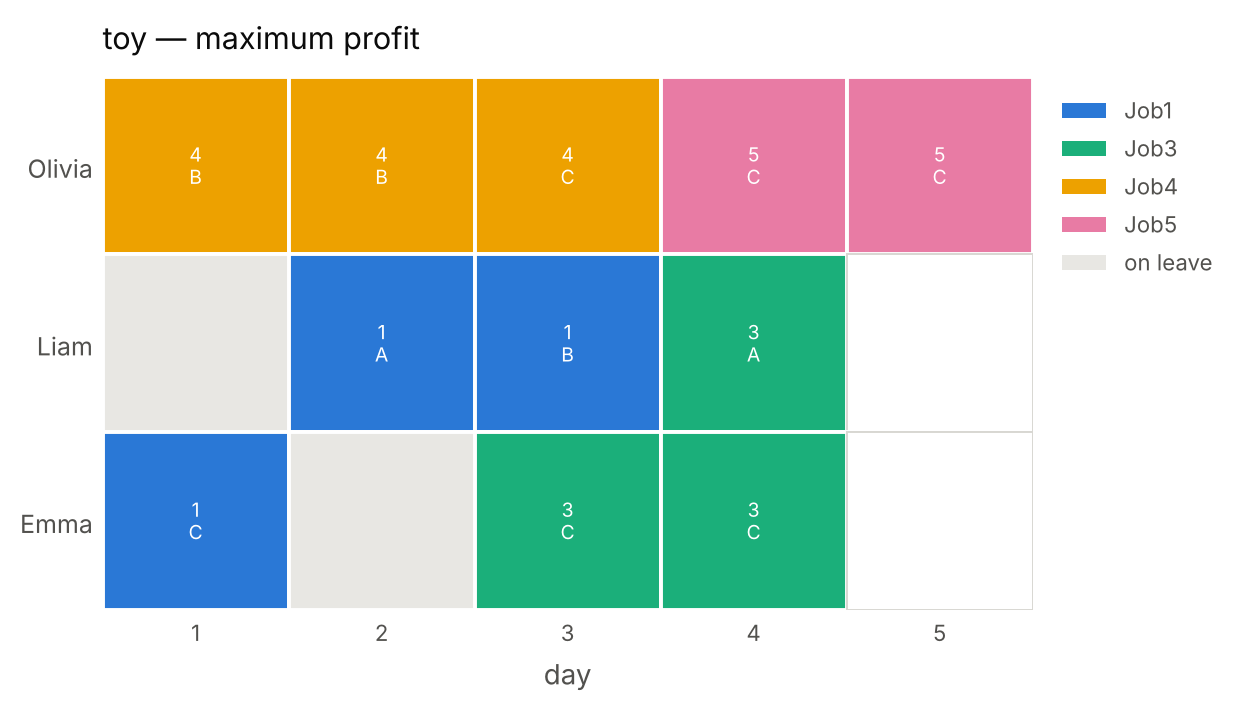

In [7]:
sol = co.solve(toy, "profit")
co.plot_schedule(toy, sol, title="toy — maximum profit")
plt.show()

Reading the chart: one row per person, one column per day. A filled cell says
which job and which qualification that person worked that day; grey is leave.
This is the **decision space** view the project asks for — an individual
solution, shown as the schedule it actually is.

Notice what maximum profit alone produces: Job2 is dropped entirely, and people
hop between jobs. Nothing in $f_1$ discourages that, which is exactly why the
other two objectives exist.

## 4. Three objectives: what "best" means now

With one objective, solutions are totally ordered and there is a single best.
With three there is usually no solution that is best on all of them, so the
comparison that replaces "better" is **dominance**:

> Solution $a$ **dominates** $b$ when $a$ is at least as good as $b$ on every
> objective and strictly better on at least one.

A solution that nothing dominates is **non-dominated**, or Pareto-optimal. The
set of all of them is the **Pareto front**, and that set — not a single
schedule — is the answer to the problem.

Two things follow that are worth being clear about:

- No Pareto-optimal solution is "the best one". Picking among them needs a
  preference the model does not contain.
- Every solution that is *not* on the front can be discarded without argument:
  something else beats it outright.

In [8]:
# dominance on three concrete toy solutions
a = (65, 3, 2)     # profit 65, longest project 3 days, at most 2 projects/person
b = (65, 2, 3)
c = (55, 2, 2)

for x, y in [(a, b), (b, a), (a, c), (c, a), (b, c)]:
    verdict = "dominates" if co.dominates(x, y) else "does not dominate"
    print(f"{str(x):<14} {verdict:<18} {y}")

(65, 3, 2)     does not dominate  (65, 2, 3)
(65, 2, 3)     does not dominate  (65, 3, 2)
(65, 3, 2)     does not dominate  (55, 2, 2)
(55, 2, 2)     does not dominate  (65, 3, 2)
(65, 2, 3)     does not dominate  (55, 2, 2)


None of those three dominates another, so all three are on the front: $a$ keeps
people on fewer projects, $b$ finishes the longest project a day sooner, $c$ is
worse on profit but matches the best of both on the other two.

A dominated point for contrast — anything with profit below 65 while matching
$a$ on the other two is beaten by $a$ outright:

In [9]:
print(co.dominates((65, 3, 2), (50, 3, 3)))   # better profit, equal duration, fewer projects

True


## 5. Computing the complete front

### 5.1 Why not a weighted sum

The obvious approach is to maximise $w_1 f_1 - w_2 f_2 - w_3 f_3$ for many
weight vectors. It is easy and it is wrong for this problem, for a reason that
is structural rather than a matter of tuning:

> A weighted sum is a **linear** function of the objective vector, so its
> maximum over a set of points always lies on the **convex hull** of that set.

Pareto fronts of integer programs are not convex. Points that sit in a dent of
the front — *unsupported* solutions — are non-dominated but are never the unique
maximum of any weighted sum, for any weights at all. §6 shows how many points
this actually loses on the toy instance.

### 5.2 The ε-constraint method

Optimise one objective and turn the others into constraints:

$$
\max\ f_1 \qquad \text{s.t.}\qquad f_2 \le \varepsilon_2,\quad f_3 \le \varepsilon_3
$$

then sweep $(\varepsilon_2, \varepsilon_3)$. Because $f_2$ and $f_3$ are
integers with small ranges — $f_2 \le h$ and $f_3 \le |\mathcal J|$ — the sweep
can cover *every* integer pair, and then it finds every Pareto-optimal point.

**Why it is complete.** Let $P = (p, d, q)$ be any Pareto-optimal point. The
cell $(\varepsilon_2, \varepsilon_3) = (d, q)$ is in the grid. At that cell the
method maximises profit subject to $f_2 \le d$ and $f_3 \le q$. $P$ is feasible
there, so the optimum $p^\star \ge p$. If $p^\star > p$, that cell's optimal
solution would dominate $P$ — contradiction. So $p^\star = p$, and $P$ is
returned. No Pareto point can be missed.

**Why it is affordable.** The grid has $(h+1)(|\mathcal J|+1)$ cells — 368 on
the medium instance — but almost none of them need a solve. If a *looser* cell
has already been solved and its optimal solution happens to respect the tighter
bounds, that solution is optimal here too: the tighter problem cannot beat the
looser one, and this solution already attains the looser optimum. Scanning from
loosest to tightest makes that test cheap, and it fires on most of the grid.

### 5.3 One detail: breaking ties

Asked only for maximum profit, a solver returns *some* profit-optimal schedule —
possibly one that drags on pointlessly, since nothing in $f_1$ cares. That would
put a weakly dominated point on the front. The fix is to add a tiny term to the
objective,

$$\max\ f_1 - \delta\,(T_{\max} + P_{\max}),$$

with $\delta$ small enough that it can never change $f_1$ (all three objectives
are integral, so $\delta \times \text{largest possible secondary term} < 1$
suffices). This is the augmentation step of the AUGMECON method.

In [10]:
res_toy = cached("toy_front", lambda: co.epsilon_constraint(toy))
print(co.front_table(res_toy["front"], toy))
print()
print(f"{res_toy['n_solves']} solves out of {res_toy['n_cells']} grid cells "
      f"({100*res_toy['n_reused']/res_toy['n_cells']:.0f}% reused), "
      f"{res_toy['runtime']:.1f}s")

  #   profit   longest   per empl.   jobs done
------------------------------------------------
  0       65         3           2         4/5
  1       65         2           3         4/5
  2       59         1           4         4/5
  3       55         2           2         3/5
  4       49         1           3         3/5
  5       42         3           1         3/5
  6       37         1           2         2/5
  7       30         2           1         2/5
  8       20         1           1         1/5
  9        0         0           0         0/5

11 solves out of 36 grid cells (69% reused), 1.0s


Ten non-dominated solutions, from 11 solves instead of 36. Read the table as the
menu CompuOpti actually has: 65 is the most money available, and it costs either
a 3-day project or somebody carrying 3 projects. Dropping to 55 buys both.

The last row — profit 0, do nothing — is formally Pareto-optimal, because
nothing beats it on the two minimised objectives. It is a good sanity check
that the front is complete, and no one would choose it.

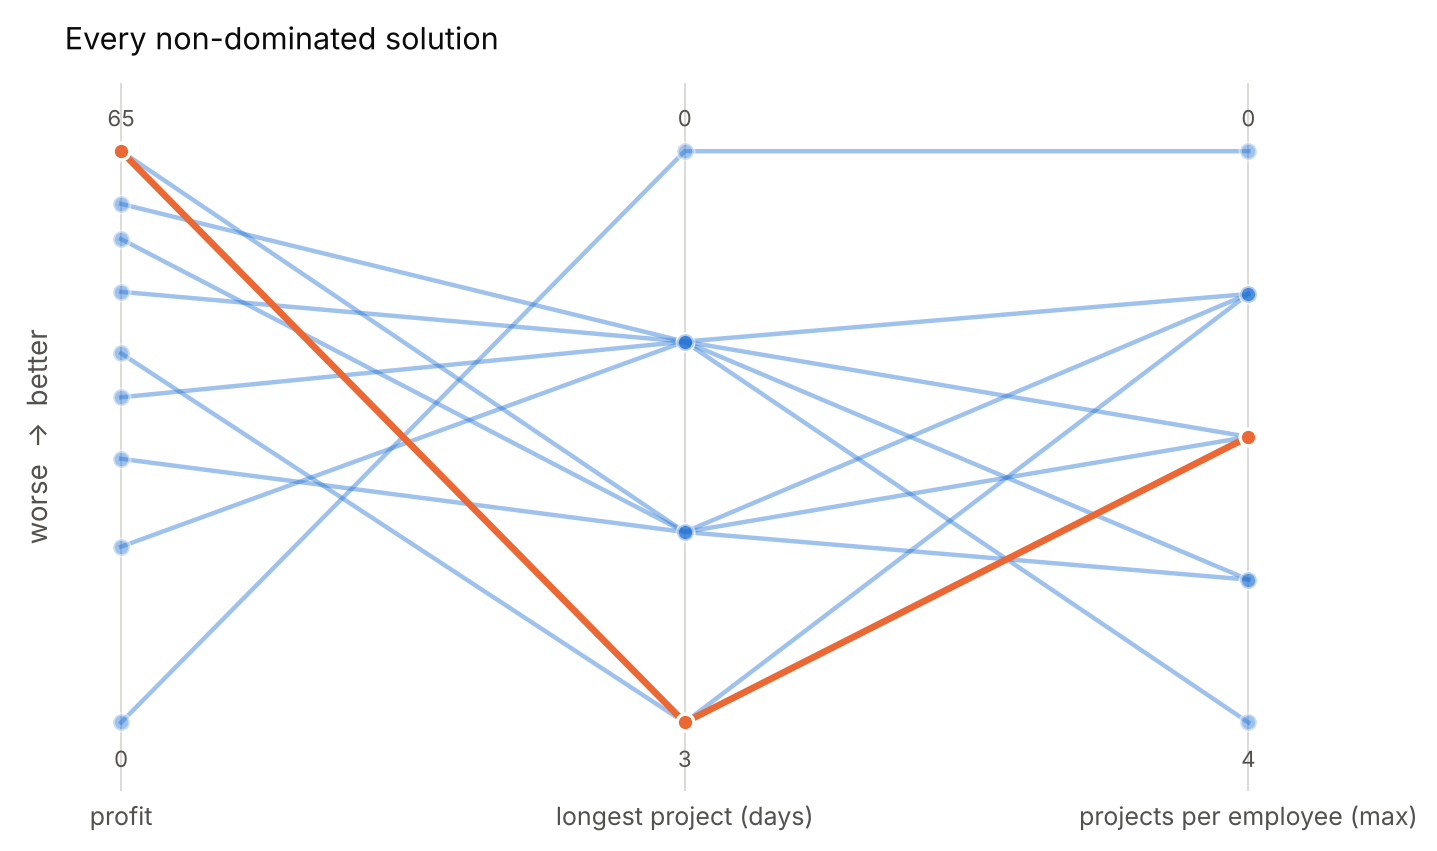

In [11]:
co.plot_parallel(res_toy["front"], highlight=(65, 3, 2))
plt.show()

Each line is one non-dominated solution; every axis is drawn so **up is better**.
The structure of a Pareto front is visible directly: no line is above all the
others everywhere, because any line that were would dominate them.

The highlighted line is the profit-maximal solution with the fewest projects per
person. It is at the top of the profit axis and pays for it on the other two.

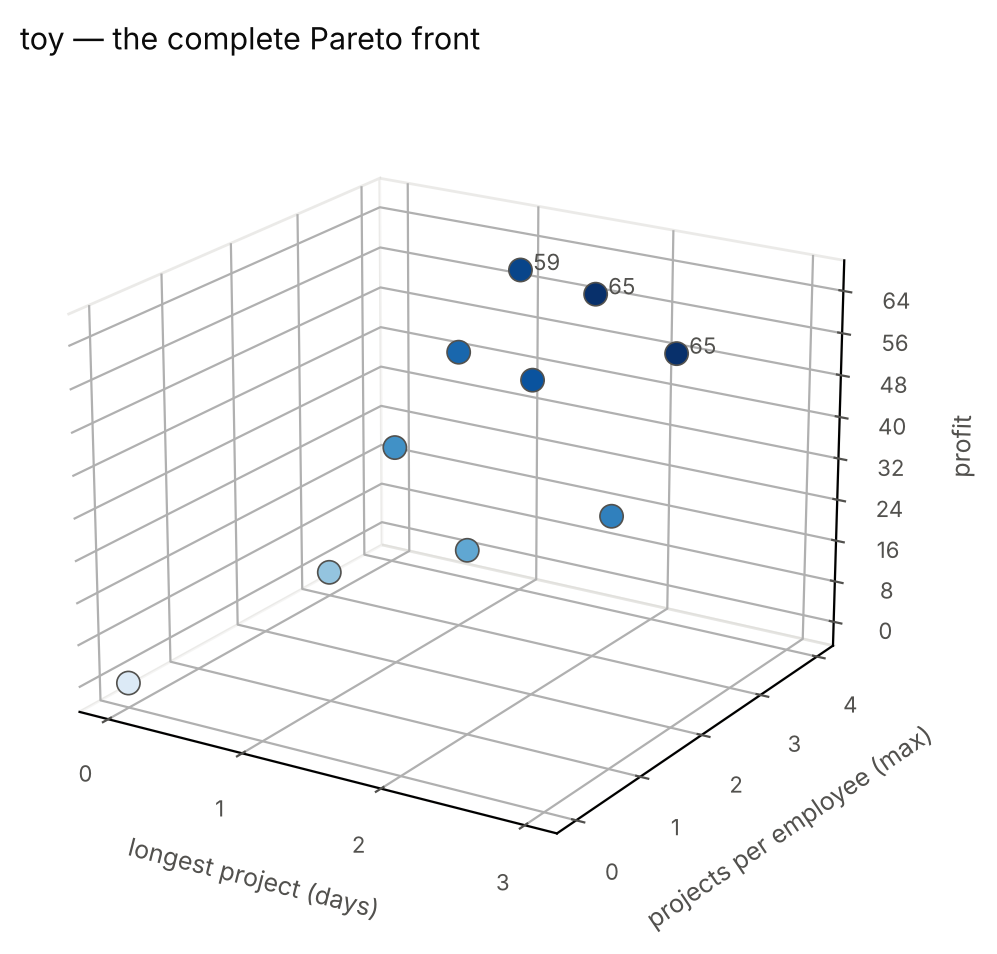

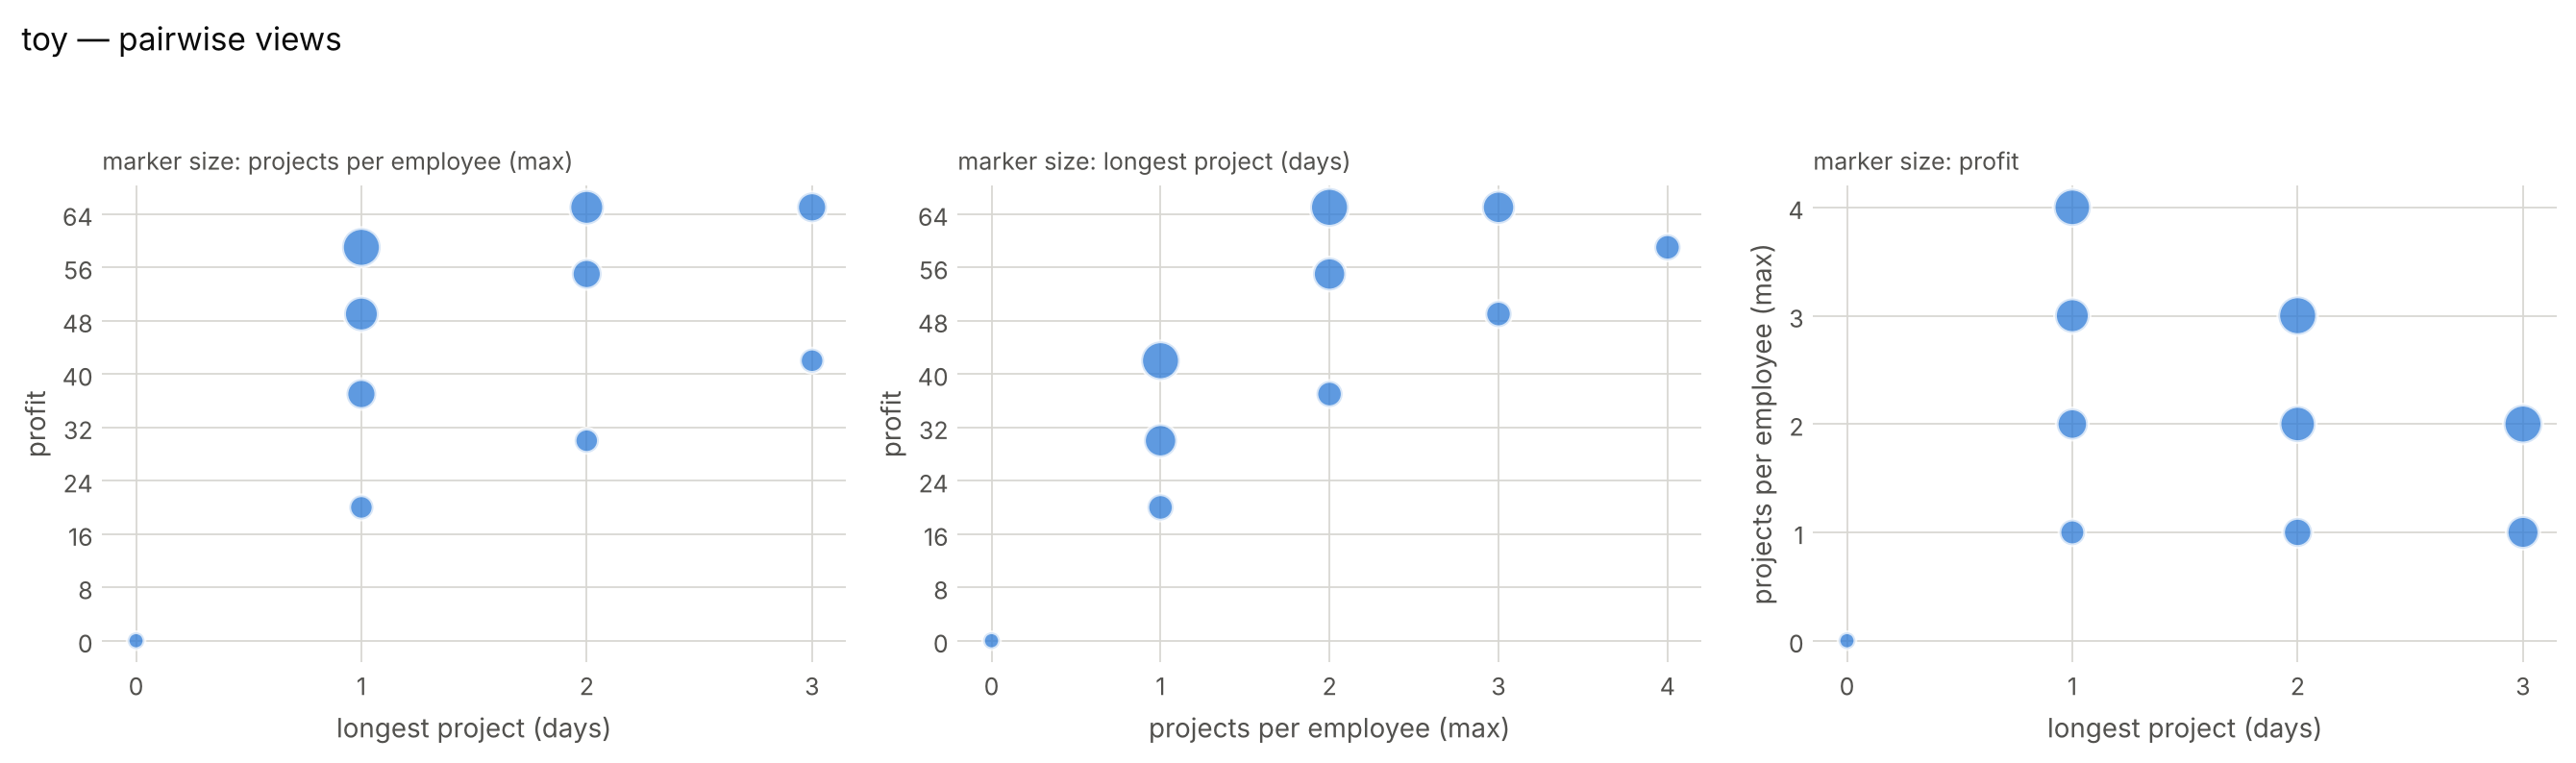

In [12]:
co.plot_front_3d(res_toy["front"], title="toy — the complete Pareto front")
plt.show()
co.plot_front_projections(res_toy["front"], title="toy — pairwise views")
plt.show()

### 5.4 The weighted sum, measured

Same instance, same model, weights swept over a grid — and the comparison the
§5.1 argument predicts.

In [13]:
ws_toy = cached("toy_weighted", lambda: co.weighted_sum(toy, steps=8))
eps_pts = {s.objectives for s in res_toy["front"]}
ws_pts = {s.objectives for s in ws_toy["front"]}

print(f"epsilon-constraint: {len(eps_pts)} non-dominated points, "
      f"{res_toy['n_solves']} solves")
print(f"weighted sum:       {len(ws_pts)} distinct points, "
      f"{ws_toy['n_solves']} solves")
print(f"missed by the weighted sum: {sorted(eps_pts - ws_pts, reverse=True)}")

epsilon-constraint: 10 non-dominated points, 11 solves
weighted sum:       6 distinct points, 45 solves
missed by the weighted sum: [(49, 1, 3), (37, 1, 2), (30, 2, 1), (20, 1, 1)]


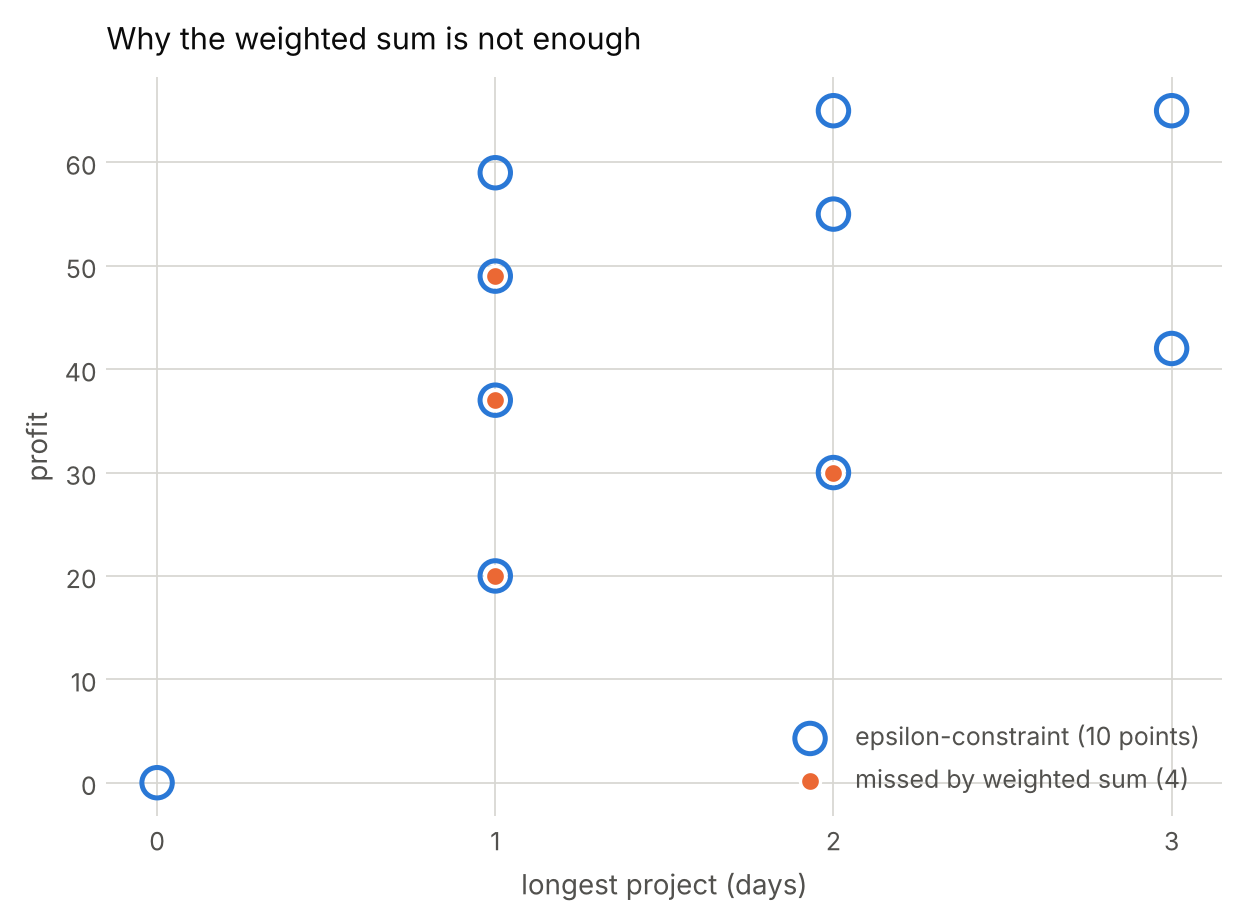

In [14]:
co.plot_method_comparison(res_toy["front"], ws_toy["front"])
plt.show()

## 6. Results on the three given instances

The toy front is in §5. Medium and large are computed by the same code; the
results are cached because the large instance takes a while.

In [15]:
res_medium = cached("medium_front", lambda: co.epsilon_constraint(medium, time_limit=60))
print(co.front_table(res_medium["front"], medium))
print()
print(f"{res_medium['n_solves']} solves out of {res_medium['n_cells']} cells, "
      f"{res_medium['runtime']:.0f}s")

  #   profit   longest   per empl.   jobs done
------------------------------------------------
  0      413        10           5       11/15
  1      413         8           6       11/15
  2      411         7           6       11/15
  3      411         6           7       11/15
  4      410         8           5       11/15
  5      408         6           6       11/15
  6      406         5           7       11/15
  7      405        12           4       11/15
  8      404         9           4       11/15
  9      401         8           4       11/15
 10      398         7           5       10/15
 11      392         6           5       11/15
 12      392         5           6       10/15
 13      385         6           4       10/15
 14      382        12           3       10/15
 15      382         5           5       10/15
 16      379         9           3       10/15
 17      370         8           3        9/15
 18      361         4           6        9/15
 19      34

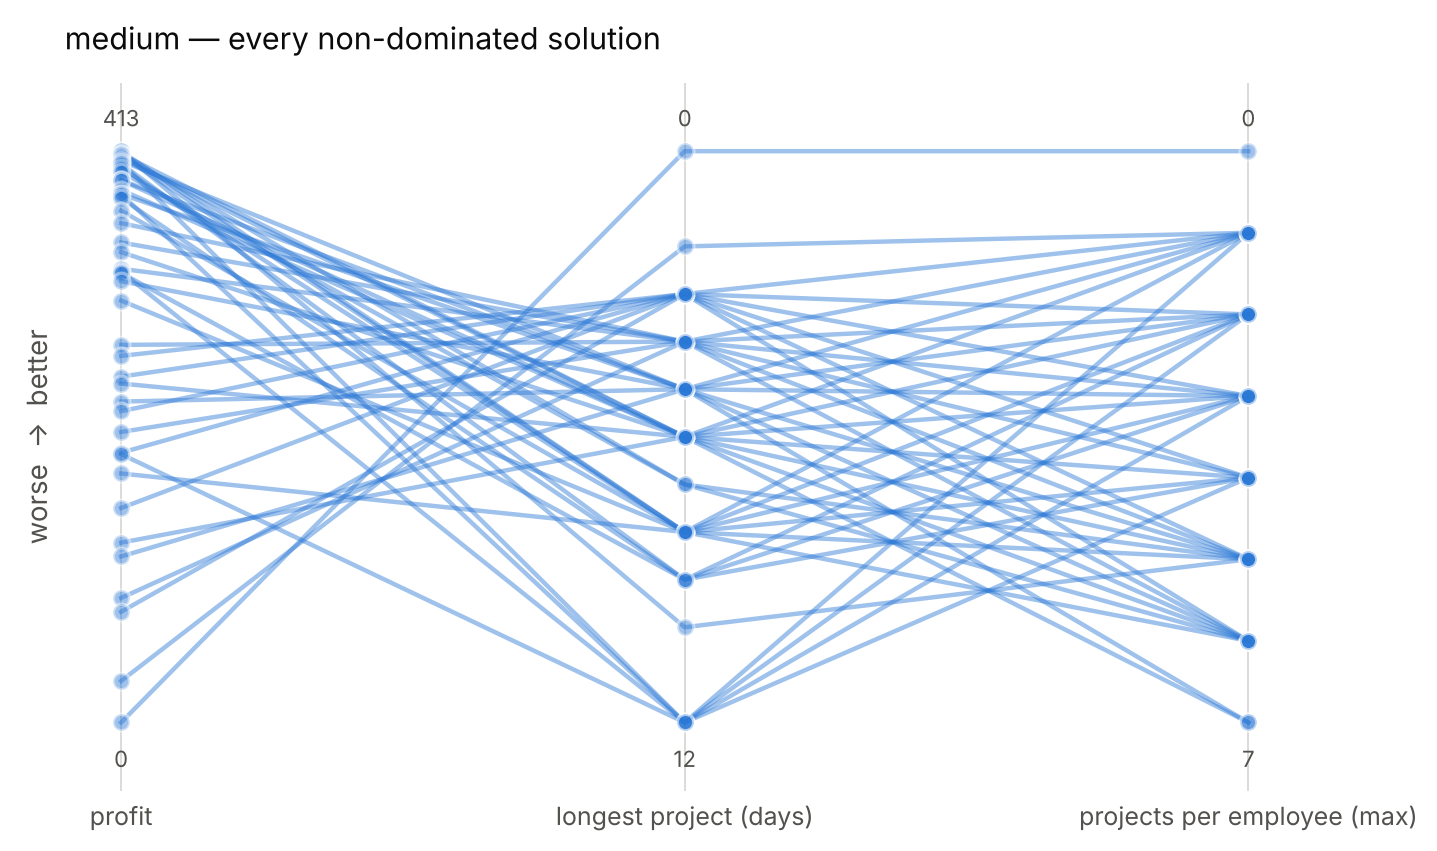

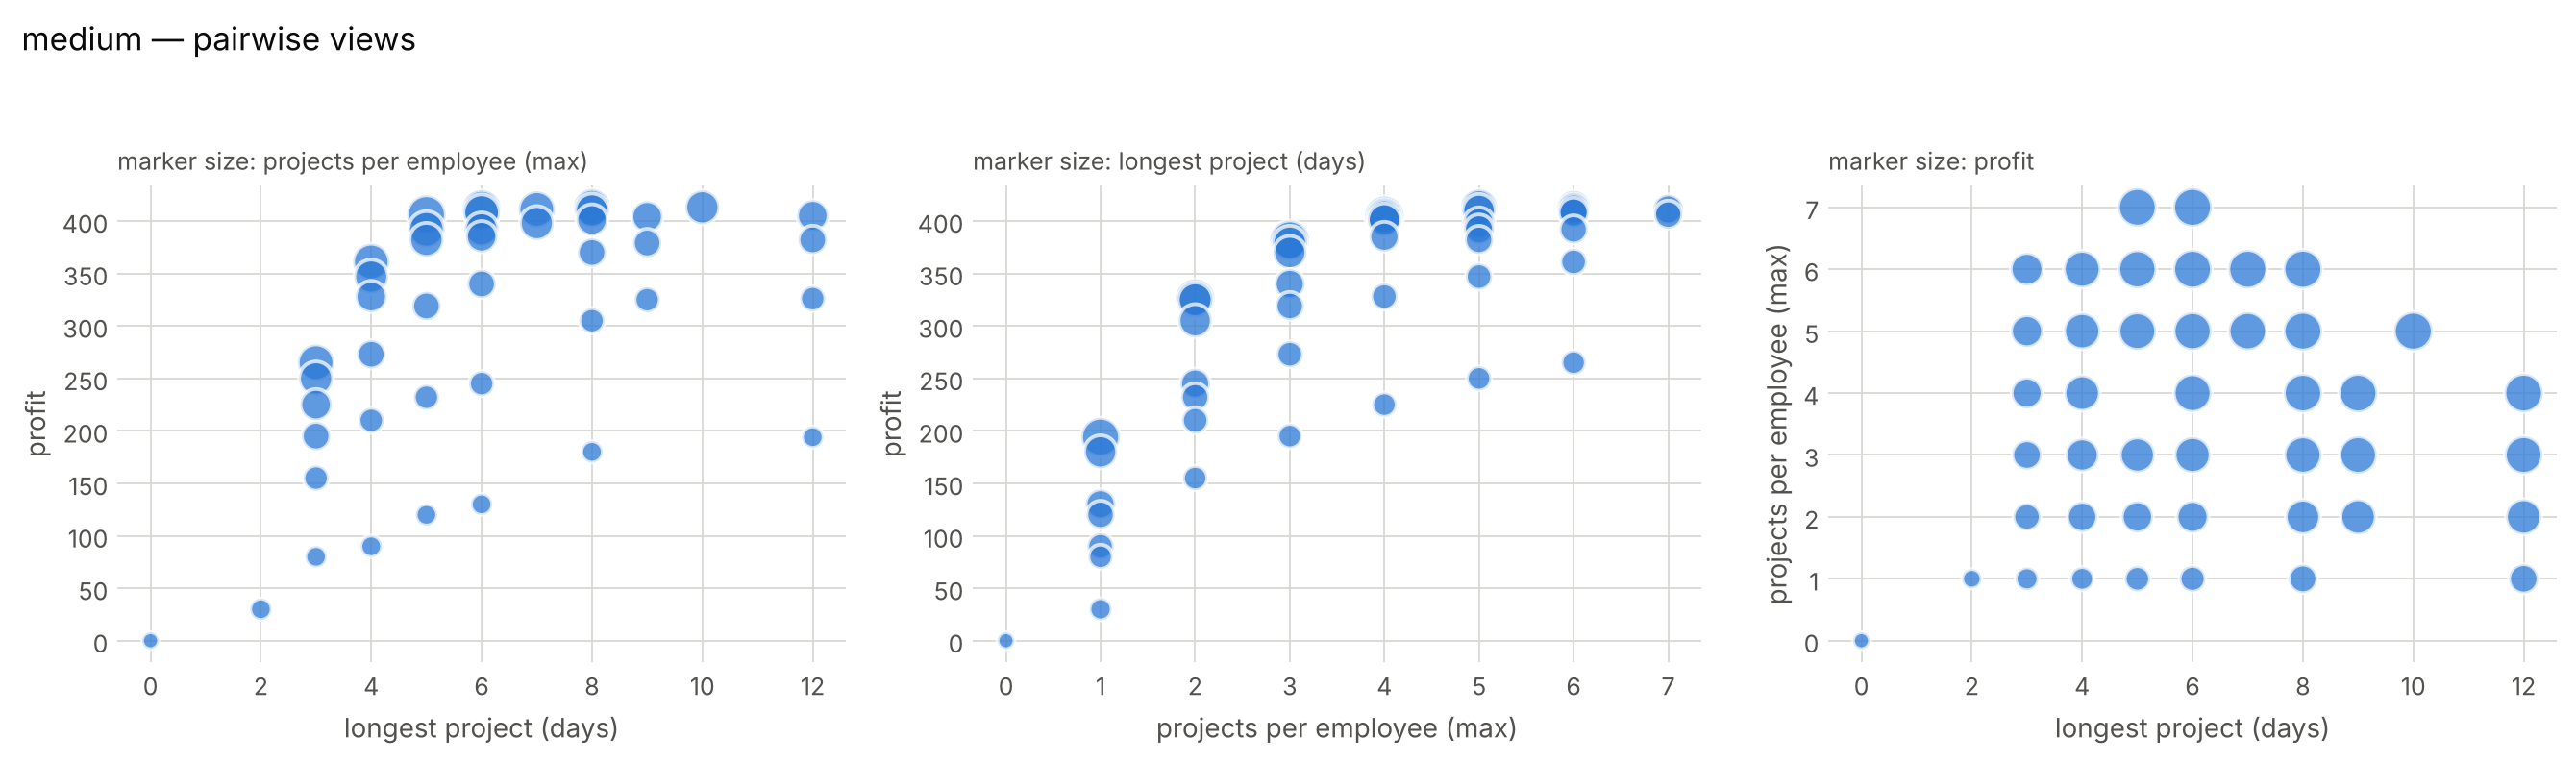

In [16]:
co.plot_parallel(res_medium["front"], title="medium — every non-dominated solution")
plt.show()
co.plot_front_projections(res_medium["front"], title="medium — pairwise views")
plt.show()

In [17]:
# The large model has 5 054 variables, past the cap of the licence that ships
# with `pip install gurobipy`, so this run used HiGHS with the grid coarsened
# to every second value and a 60 s cap per solve. It is therefore an
# approximation: every point below is genuinely non-dominated, but points
# between grid lines are missed, and a capped solve can stop short of the
# optimum. On a full Gurobi licence, run it exactly with
#     co.epsilon_constraint(large, step=1, backend="gurobi")
res_large = cached("large_front",
                   lambda: co.epsilon_constraint(large, backend="highs",
                                                 step=2, time_limit=60))
print(co.front_table(res_large["front"], large))
print()
print(f"{res_large['n_solves']} solves out of {res_large['n_cells']} cells, "
      f"{res_large['runtime']:.0f}s, step {res_large['step']}, "
      f"exact: {res_large['exact']}")
print(f"best profit found here: {max(s.profit for s in res_large['front'])}; "
      f"the true optimum is 817")

  #   profit   longest   per empl.   jobs done
------------------------------------------------
  0      790         8          10       17/25
  1      779        10           8       16/25
  2      776        10           7       16/25
  3      764         8           9       16/25
  4      625        30           5       13/25
  5      476        29           3        9/25
  6      290        18           1        5/25
  7      115         2           3        3/25
  8       80         4           1        2/25
  9        0         0           0        0/25

18 solves out of 266 cells, 910s, step 2, exact: False
best profit found here: 790; the true optimum is 817


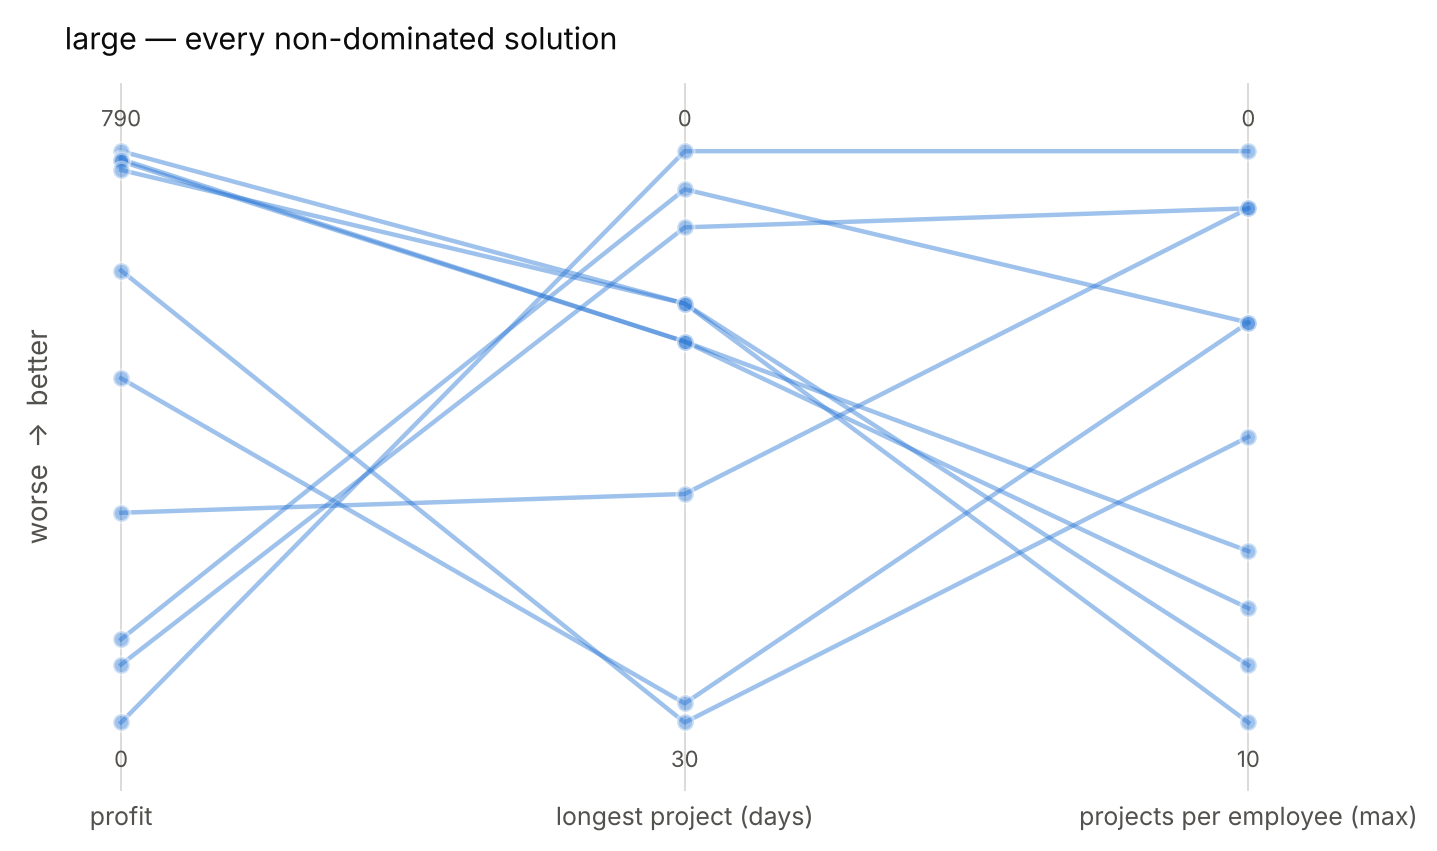

In [18]:
co.plot_parallel(res_large["front"], title="large — every non-dominated solution")
plt.show()

### Reading one solution from the front

The front is the answer, but a decision-maker eventually picks one point. Below,
two points from the medium front and the schedules behind them — the objective
space and decision space views the project asks to connect.

most profitable    profit  413   longest project 10d   max 5 projects/person   11 jobs done


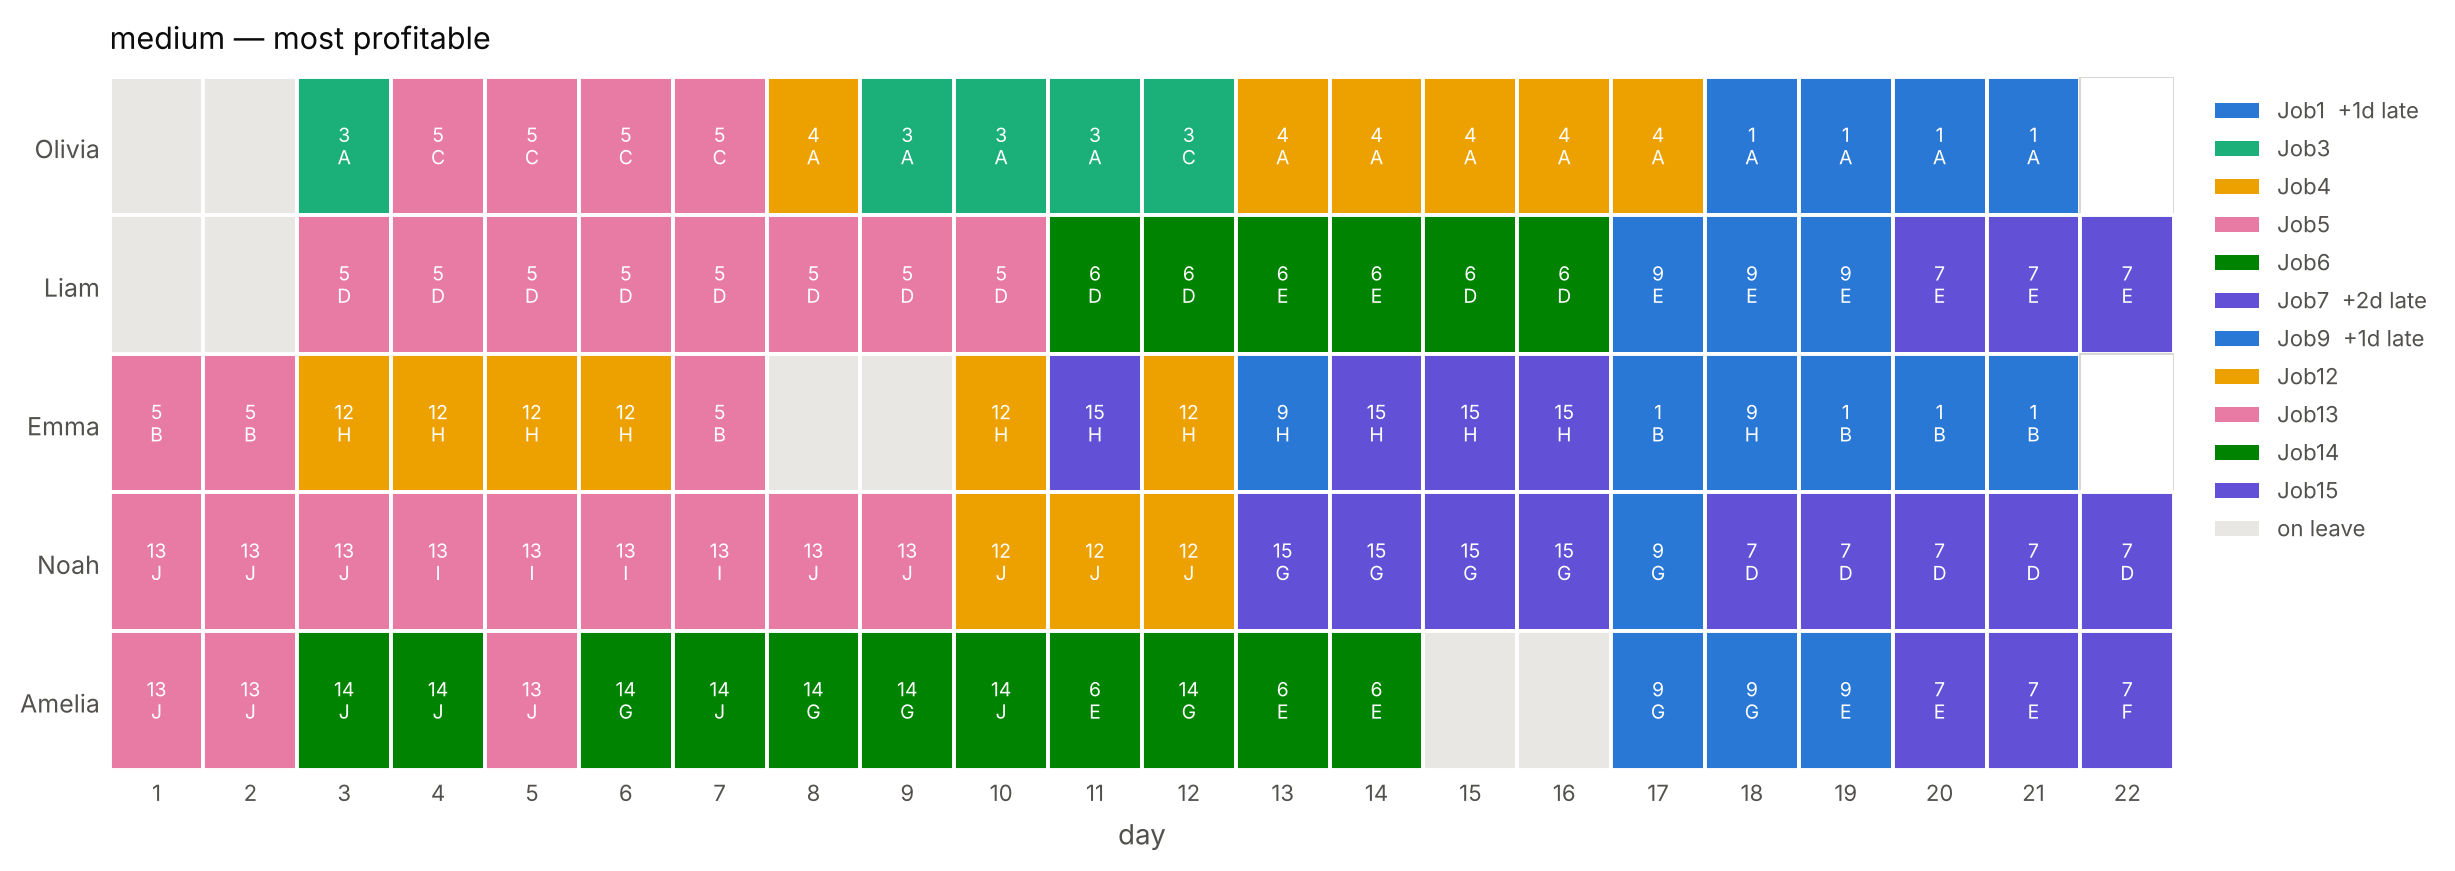

kindest to staff   profit    0   longest project  0d   max 0 projects/person   0 jobs done


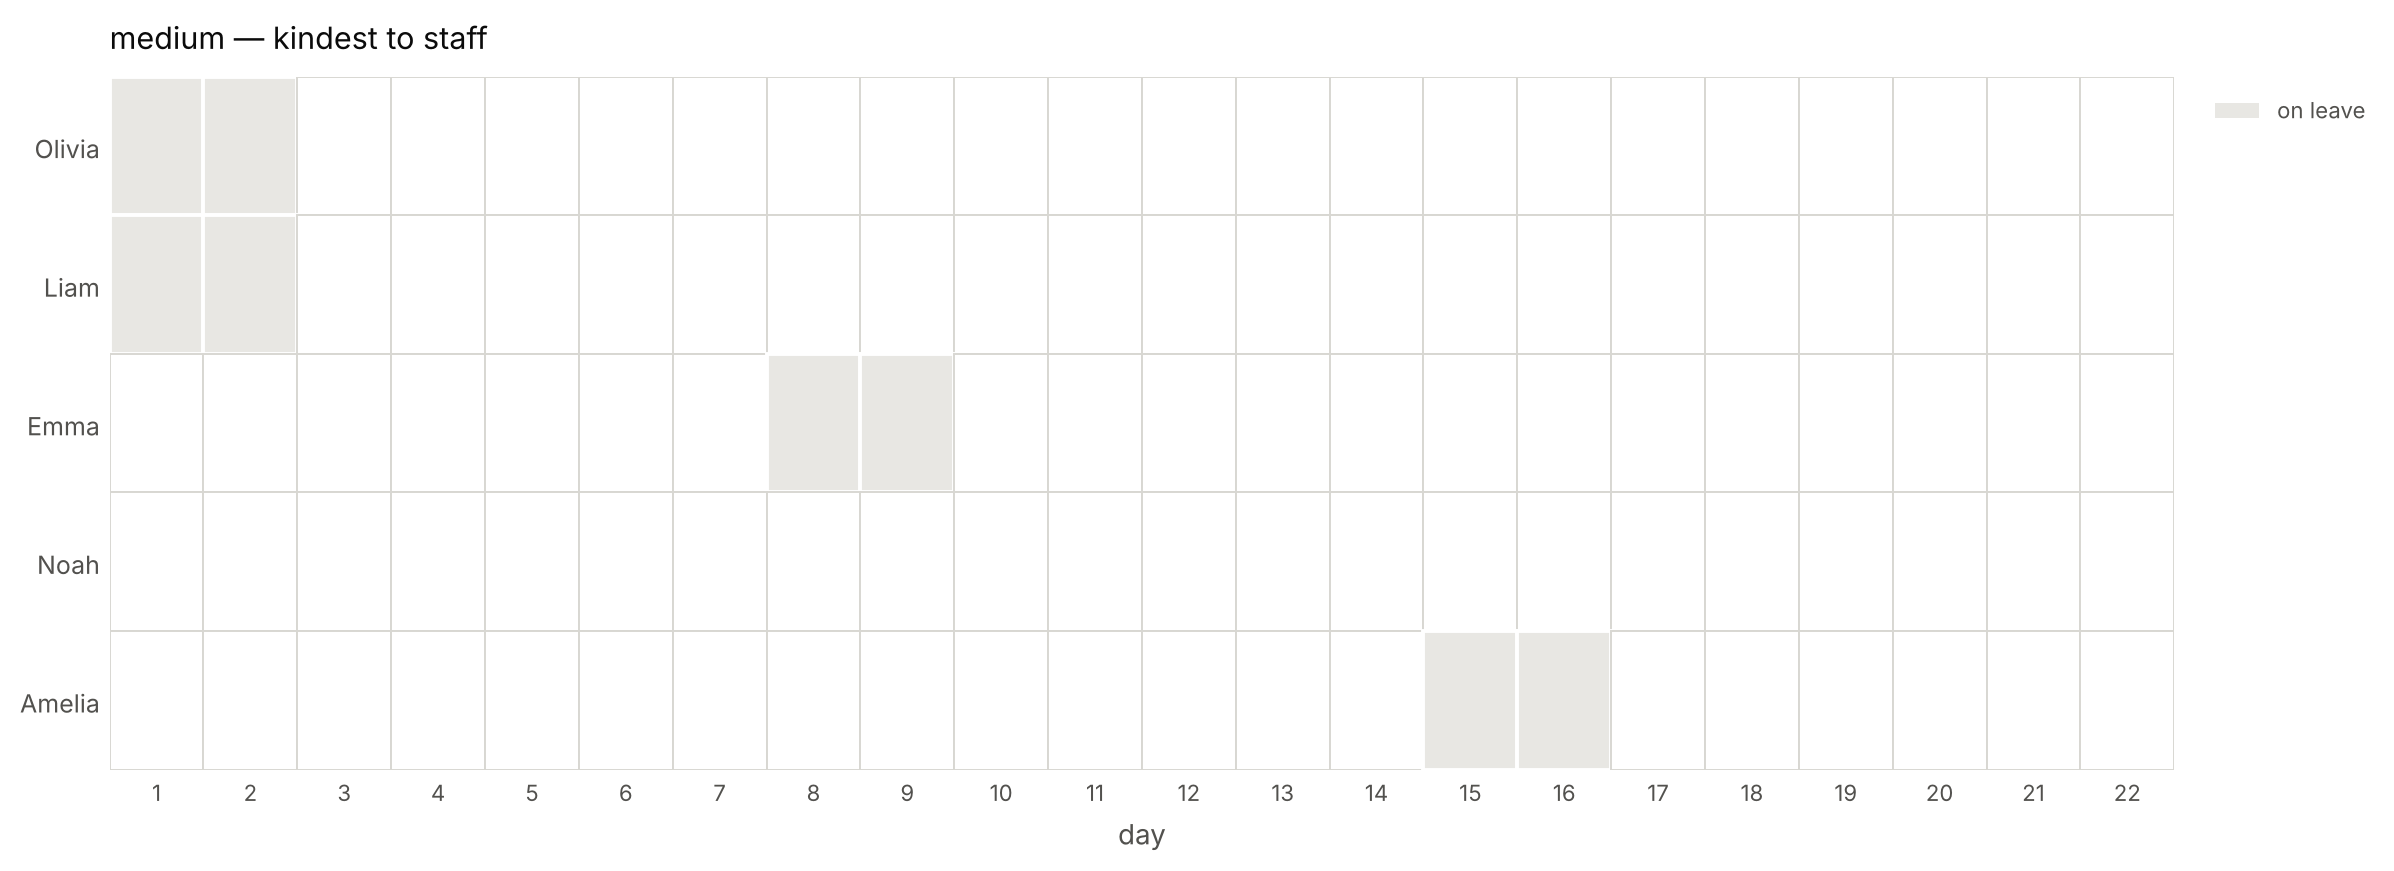

In [19]:
front = res_medium["front"]
best_profit = max(front, key=lambda s: s.profit)
fewest_projects = min(front, key=lambda s: (s.max_projects, -s.profit))

for sol, label in [(best_profit, "most profitable"), (fewest_projects, "kindest to staff")]:
    print(f"{label:<18} profit {sol.profit:>4}   longest project {sol.max_duration:>2}d   "
          f"max {sol.max_projects} projects/person   {len(sol.done)} jobs done")
    co.plot_schedule(medium, sol, title=f"medium — {label}")
    plt.show()

The difference between those two schedules is the trade-off made concrete: the
same five people, the same month, and a choice about whether the business or the
staff absorbs the pressure. That is the kind of question the CEO is actually
being asked to answer, and the model's job is to show her the real options
rather than to answer it for her.

## 7. Checking the results are right

Three independent checks, because a multi-objective result is easy to get subtly
wrong and hard to eyeball.

**1. Every schedule is feasible.** After every single solve, `verify` re-reads
the schedule and re-checks it against the problem statement: qualifications held,
leave respected, coverage exact, no work on abandoned jobs. It also recomputes
all three objective values from the schedule rather than trusting the solver's
variables. This runs on every solve in this notebook, so a modelling slip cannot
reach the results silently.

**2. Every reported point really is non-dominated.** For each point $(p,d,q)$,
three more solves ask whether anything beats it on one objective without losing
on the others.

There is a trap here worth naming, because we fell into it. The obvious test is
"the optimum of each of those three problems equals $(p,d,q)$" — but under a
time limit a solve can stop early and report a value *worse* than the point's
own, which looks like a contradiction and is really an unfinished search. On
the medium instance that produced a spurious failure on $(250,3,5)$: minimising
duration reported 4 after timing out with a 52% gap, while forcing
duration $\le 3$ solves to proven optimality and returns the point itself.

So the test is "no solve *found* anything strictly better". That conclusion is
valid even from a non-converged solve, because any incumbent is a feasible
solution. The check reports separately whether all three solves converged, so
"no counter-example found" is never silently reported as "proved".

**3. Nothing was missed.** Completeness is proved in §5.2, but the argument is
also tested: a few hundred feasible schedules are generated by optimising random
directions, and every one of them must be dominated by a point on the front.

In [20]:
failures, summary = co.check_front(toy, res_toy["front"])
print("\nfailures:", failures)
print("summary:", summary)

  point  0       (65, 3, 2)  proved


  point  1       (65, 2, 3)  proved
  point  2       (59, 1, 4)  proved


  point  3       (55, 2, 2)  proved


  point  4       (49, 1, 3)  proved
  point  5       (42, 3, 1)  proved


  point  6       (37, 1, 2)  proved


  point  7       (30, 2, 1)  proved


  point  8       (20, 1, 1)  proved
  point  9        (0, 0, 0)  proved
  -> 10/10 proved non-dominated, 0 with no counter-example found, 0 failures

failures: []
summary: {'points': 10, 'proved': 10, 'failures': 0}


In [21]:
missed = co.search_for_missed_points(toy, res_toy["front"], n=300)
print(f"random schedules not dominated by the front: {missed}")

random schedules not dominated by the front: []


## 8. A generator, and how the method scales

`generate_instance` produces instances in the same JSON format, with a seed so
results reproduce. Every qualification is guaranteed to be held by somebody, so
a job is never impossible for lack of a skill; instances can still be partly
unachievable through lack of capacity, which is the interesting case.

In [22]:
demo = co.generate_instance(n_staff=4, n_jobs=6, horizon=10,
                            n_qualifications=4, seed=7, name="demo")
print(co.instance_stats(demo))
demo_front = co.epsilon_constraint(demo)["front"]
print()
print(co.front_table(demo_front, demo))

{'instance': 'demo', 'staff': 4, 'jobs': 6, 'quals': 4, 'horizon': 10, 'demand': 40, 'capacity': 36, 'load': 1.11, 'total_gain': 370}



  #   profit   longest   per empl.   jobs done
------------------------------------------------
  0      302         5           3         5/6
  1      255         7           2         4/6
  2      252         5           2         4/6
  3      235         3           2         4/6
  4      235         2           3         4/6
  5      187         7           1         3/6
  6      185         5           1         3/6
  7      185         2           2         3/6
  8      130         3           1         2/6
  9       70         2           1         1/6
 10        0         0           0         0/6


In [23]:
perf = cached("performance", lambda: None)
if perf is None:
    print("run `python scripts/performance.py` to produce results/performance.pkl")
else:
    rows = perf["rows"]
    head = f"{'instance':<16}{'vars':>7}{'cons':>7}{'1 solve':>9}{'front':>9}{'points':>8}{'solves':>8}{'reuse':>8}"
    print(head); print("-" * len(head))
    for r in rows:
        print(f"{r['instance'][:16]:<16}{r['n_vars']:>7}{r['n_constrs']:>7}"
              f"{r['t_single']:>8.1f}s{r['t_front']:>8.1f}s{r['front_size']:>8}"
              f"{r['n_solves']:>8}{r['reuse_pct']:>7.0f}%")

instance           vars   cons  1 solve    front  points  solves   reuse
------------------------------------------------------------------------
gen_s3_j5_h8_see    227    193     0.1s     1.0s       7      10     82%
gen_s4_j7_h10_se    417    323     0.1s     2.3s      11      12     86%
gen_s4_j9_h12_se    511    457     0.1s     0.8s       9      11     92%
gen_s5_j10_h14_s   1127    604     0.7s   141.3s      23      24     86%
gen_s5_j12_h16_s   1309    787     0.5s   814.5s      24      25     89%


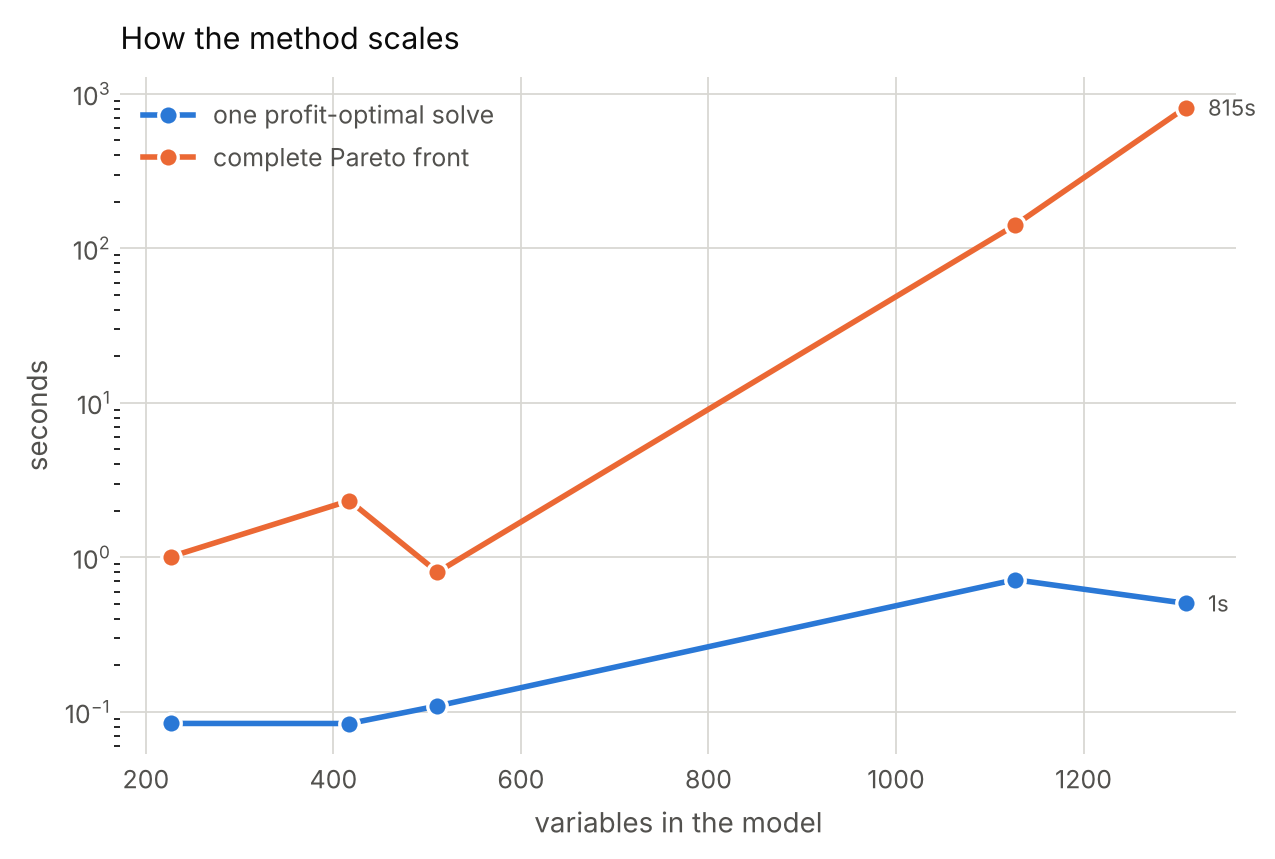

In [24]:
if perf is not None:
    co.plot_scaling(perf["rows"])
    plt.show()

What the table shows, and what to say about it at a defense:

- A **single** profit-optimal solve stays cheap well past the given instances.
  The formulation choices in §2.2 are why.
- The **front** costs roughly one to two orders of magnitude more than a single
  solve — not the full grid, because the reuse rule removes most cells, but the
  cells that remain are the hard ones, where the ε-constraints bind.
- Growth is driven by the number of $X$ variables, which is roughly
  $|\mathcal S| \times |\mathcal J| \times \overline{|\mathcal Q^J|} \times h$.
  Horizon and staff count hurt more than job count.

If an instance is too large for the exact scan, the statement explicitly allows
trading optimality for time. Two cheap options, in order of how much they cost:
coarsen the ε grid (every second value), which returns a subset of the true
front and no false points; or put a time limit on each solve, which can return
points that are not quite optimal — `solve` reports the gap so this is visible
rather than silent.

## 9. What the model does not capture

Worth being honest about, since these are the questions a jury asks.

- **Everyone is interchangeable within a qualification.** No seniority, no
  individual productivity, no preference for particular clients.
- **Tasks are perfectly divisible by day and freely interruptible.** A job can
  be dropped on day 3 and picked up on day 11 at no cost. Real projects have
  ramp-up costs that would push towards contiguous blocks, which the model only
  discourages indirectly through $f_2$.
- **No precedence between qualifications.** Design before implementation, say,
  is not expressible. It would need ordering constraints between the end of one
  qualification's days and the start of another's.
- **Leave and due dates are certain.** Nothing is stochastic.
- **$f_2$ is the longest single project**, not the makespan. Minimising the
  makespan instead is a one-line change ($T_{\max} \ge E_j$ rather than
  $T_{\max} \ge D_j$) and gives a different, equally defensible front.
- **The empty schedule is on the front.** Formally correct, practically useless.
  It could be excluded by requiring a minimum profit, but leaving it in makes the
  completeness of the scan easy to see.